# LSTM Transfer Learning for Time-Series Forecasting

In [24]:
import random, copy, json, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import mean_squared_error, mean_absolute_error
from statsmodels.datasets import co2, elnino
from IPython.display import display
SEED=42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.set_num_threads(min(4,torch.get_num_threads()))
DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', DEVICE)

Device: cuda


## 1. Load both real time series

Source series: 2284 weekly readings: 1958-03-29 to 2001-12-29
Target series: 252 monthly readings: 1990-01-01 to 2010-12-01


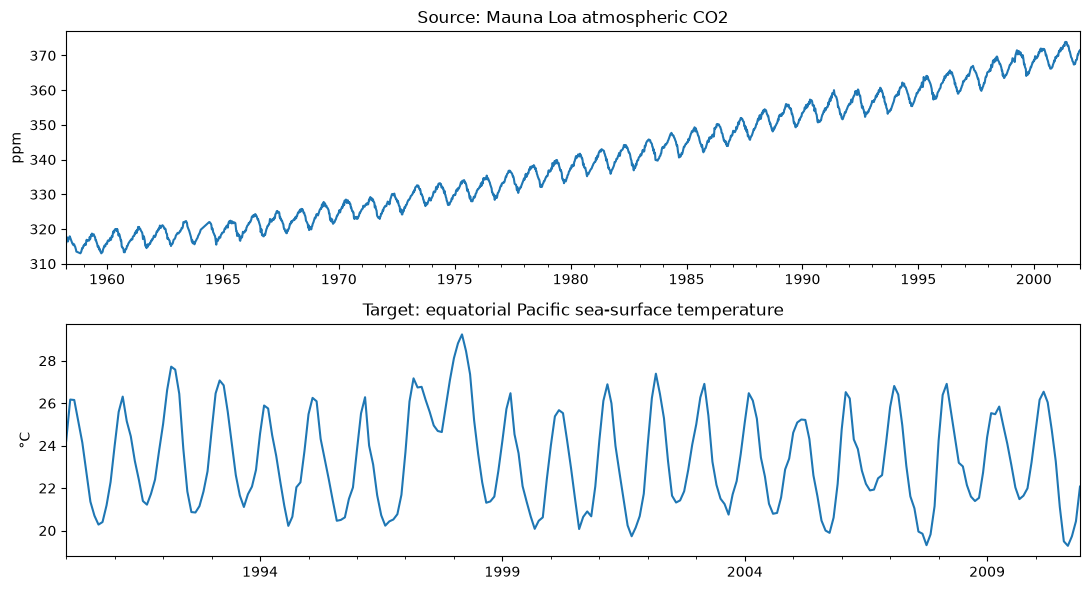

In [25]:
source=co2.load_pandas().data['co2'].astype(float).interpolate(limit_direction='both')
source.index=pd.to_datetime(source.index)
raw=elnino.load_pandas().data
month_names=['JAN','FEB','MAR','APR','MAY','JUN','JUL','AUG','SEP','OCT','NOV','DEC']
target_values=raw[month_names].to_numpy(dtype=float).reshape(-1)
target_dates=pd.date_range('1950-01-01',periods=len(target_values),freq='MS')
target=pd.Series(target_values,index=target_dates,name='Pacific sea-surface temperature').loc['1990':'2010']
assert not source.isna().any() and not target.isna().any()
print('Source series:',len(source),'weekly readings:',source.index.min().date(),'to',source.index.max().date())
print('Target series:',len(target),'monthly readings:',target.index.min().date(),'to',target.index.max().date())
fig,ax=plt.subplots(2,1,figsize=(11,6))
source.plot(ax=ax[0],title='Source: Mauna Loa atmospheric CO2',ylabel='ppm')
target.plot(ax=ax[1],title='Target: equatorial Pacific sea-surface temperature',ylabel='°C')
plt.tight_layout(); plt.show()

## 2. Chronological split, scaling and sliding windows

In [26]:
WINDOW=12
source_array=source.to_numpy(np.float32)
target_array=target.to_numpy(np.float32)
s_train_end=int(len(source_array)*.85)
t_train_end=int(len(target_array)*.60)
t_val_end=int(len(target_array)*.80)

source_mean,source_std=source_array[:s_train_end].mean(),source_array[:s_train_end].std()
target_mean,target_std=target_array[:t_train_end].mean(),target_array[:t_train_end].std()
S=(source_array-source_mean)/source_std
T=(target_array-target_mean)/target_std

def make_windows(array,first_index,last_index,window=WINDOW):
    # index of the value to predict; all preceding values in the input occur earlier
    X=np.stack([array[i-window:i] for i in range(first_index,last_index)])
    Y=np.asarray([array[i] for i in range(first_index,last_index)])
    return torch.tensor(X[:,:,None],dtype=torch.float32),torch.tensor(Y[:,None],dtype=torch.float32)

xs,ys=make_windows(S,WINDOW,s_train_end)
xs_val,ys_val=make_windows(S,s_train_end,len(S))
xt,yt=make_windows(T,WINDOW,t_train_end)
xt_val,yt_val=make_windows(T,t_train_end,t_val_end)
xt_test,yt_test=make_windows(T,t_val_end,len(T))
print('Source train/val windows:',len(xs),len(xs_val))
print('Target train/val/test windows:',len(xt),len(xt_val),len(xt_test))
print('Target test period:',target.index[t_val_end].date(),'to',target.index[-1].date())
print('One training window:',xt[0,:,0].numpy().round(2))

Source train/val windows: 1929 343
Target train/val/test windows: 139 50 51
Target test period: 2006-10-01 to 2010-12-01
One training window: [ 0.29  1.12  1.11  0.69  0.26 -0.33 -0.93 -1.21 -1.39 -1.33 -1.   -0.53]


## 3. LSTM architecture and training helper

In [27]:
class ForecastLSTM(nn.Module):
    def __init__(self):
        super().__init__()
        self.lstm=nn.LSTM(input_size=1,hidden_size=32,batch_first=True)
        self.head=nn.Linear(32,1)
    def forward(self,x):
        _,(h,_) = self.lstm(x)
        return self.head(h[-1])

def fit_model(model,train,valid,epochs=35,lr=.003,patience=8):
    model=model.to(DEVICE)
    optim=torch.optim.Adam(model.parameters(),lr=lr)
    loss_fn=nn.MSELoss()
    loader=DataLoader(TensorDataset(*train),batch_size=64,shuffle=True)
    best=float('inf'); best_weights=None; stale=0
    history={'train':[],'val':[]}
    for epoch in range(epochs):
        model.train(); losses=[]
        for xb,yb in loader:
            xb,yb=xb.to(DEVICE),yb.to(DEVICE)
            optim.zero_grad(); loss=loss_fn(model(xb),yb)
            loss.backward(); nn.utils.clip_grad_norm_(model.parameters(),1.0); optim.step()
            losses.append(loss.item()*len(xb))
        tr=sum(losses)/len(loader.dataset)
        model.eval()
        with torch.no_grad():
            xv,yv=valid
            va=loss_fn(model(xv.to(DEVICE)),yv.to(DEVICE)).item()
        history['train'].append(tr); history['val'].append(va)
        if va < best-1e-5:
            best=va; best_weights=copy.deepcopy(model.state_dict()); stale=0
        else:
            stale+=1
            if stale>=patience: break
    model.load_state_dict(best_weights)
    return model,history

@torch.no_grad()
def forecast(model,X):
    model.eval(); return model(X.to(DEVICE)).cpu().numpy().ravel()

print('Architecture:',ForecastLSTM())

Architecture: ForecastLSTM(
  (lstm): LSTM(1, 32, batch_first=True)
  (head): Linear(in_features=32, out_features=1, bias=True)
)


## 4. Pretrain on the source CO₂ time series

In [28]:
torch.manual_seed(SEED)
pretrained,pretrain_history=fit_model(ForecastLSTM(),(xs,ys),(xs_val,ys_val),epochs=80, lr=0.003, patience=15)
print('Pretraining epochs:',len(pretrain_history['train']))
print('Best source validation MSE:',round(min(pretrain_history['val']),4))

Pretraining epochs: 74
Best source validation MSE: 0.0018


## 5. Fine-tune on the smaller target time series

In [29]:
fine_tuned=copy.deepcopy(pretrained)
fine_tuned,ft_history=fit_model(fine_tuned,(xt,yt),(xt_val,yt_val),epochs=80, lr=0.001, patience=15)
print('Fine-tuning epochs:',len(ft_history['train']))
print('Best target validation MSE:',round(min(ft_history['val']),4))

Fine-tuning epochs: 27
Best target validation MSE: 0.0892


## 6. Train the same LSTM from scratch on the target data

In [30]:
torch.manual_seed(SEED)
scratch=ForecastLSTM()
scratch,scratch_history=fit_model(scratch,(xt,yt),(xt_val,yt_val),epochs=80, lr=0.001, patience=15)
print('Scratch-training epochs:',len(scratch_history['train']))
print('Best target validation MSE:',round(min(scratch_history['val']),4))

Scratch-training epochs: 55
Best target validation MSE: 0.0721


## 7. Compute RMSE and MAE on held-out target test data

In [31]:
y_actual=yt_test.numpy().ravel()*target_std+target_mean
pred_ft=forecast(fine_tuned,xt_test)*target_std+target_mean
pred_scratch=forecast(scratch,xt_test)*target_std+target_mean
pred_last=xt_test[:,-1,0].numpy()*target_std+target_mean

def scores(p): return {'RMSE (°C)':float(np.sqrt(mean_squared_error(y_actual,p))), 'MAE (°C)':float(mean_absolute_error(y_actual,p))}
comparison=pd.DataFrame({'Fine-tuned LSTM':scores(pred_ft),'Scratch LSTM':scores(pred_scratch),'Last-value baseline':scores(pred_last)}).T
print('Test metrics (lower is better):')
display(comparison.round(4))

ft_rmse=comparison.loc['Fine-tuned LSTM','RMSE (°C)']
sc_rmse=comparison.loc['Scratch LSTM','RMSE (°C)']
change_pct=(sc_rmse-ft_rmse)/sc_rmse*100
print(f'RMSE change relative to scratch: {change_pct:+.2f}%')
print('Transfer helped on RMSE.' if ft_rmse<sc_rmse else 'Transfer did not help on RMSE.')
with open('transfer_metrics.json','w') as f:
    json.dump({'source':'Mauna Loa weekly CO2','target':'Pacific monthly SST 1990-2010','test_count':len(y_actual),'fine_tuned':scores(pred_ft),'scratch':scores(pred_scratch),'persistence':scores(pred_last),'rmse_improvement_pct':float(change_pct)},f,indent=2)

Test metrics (lower is better):


,RMSE (°C),MAE (°C)
Fine-tuned LSTM,0.7685,0.6131
Scratch LSTM,0.7224,0.5769
Last-value baseline,1.1630,0.9710


RMSE change relative to scratch: -6.38%
Transfer did not help on RMSE.


## 8. Plot actual vs. predicted values and training losses

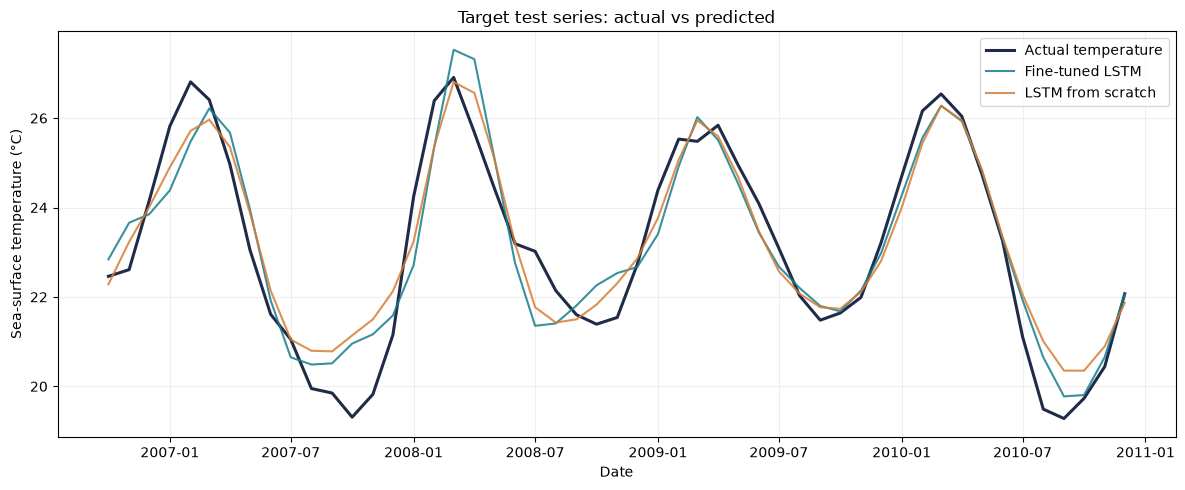

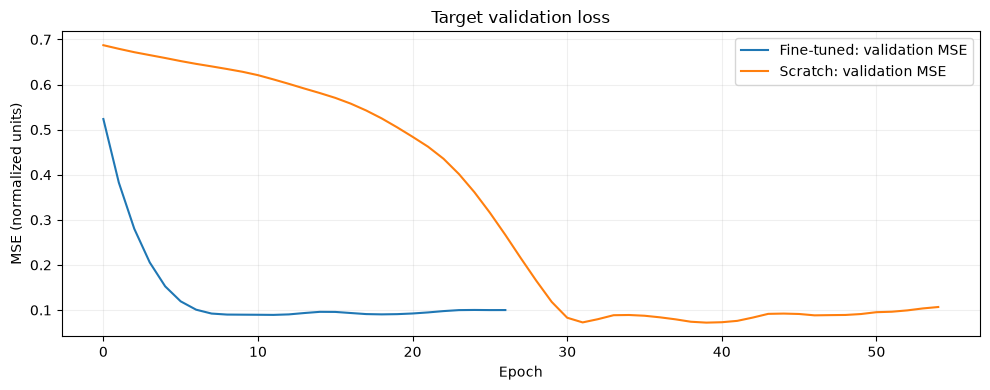

In [32]:
dates=target.index[t_val_end:]
fig,ax=plt.subplots(figsize=(12,5))
ax.plot(dates,y_actual,label='Actual temperature',lw=2.2,color='#202B48')
ax.plot(dates,pred_ft,label='Fine-tuned LSTM',alpha=.85,color='#167D8D')
ax.plot(dates,pred_scratch,label='LSTM from scratch',alpha=.85,color='#D67D35')
ax.set(title='Target test series: actual vs predicted',xlabel='Date',ylabel='Sea-surface temperature (°C)')
ax.grid(alpha=.2); ax.legend(); plt.tight_layout()
plt.savefig('transfer_actual_vs_predicted.png',dpi=180); plt.show()

fig,ax=plt.subplots(figsize=(10,4))
ax.plot(ft_history['val'],label='Fine-tuned: validation MSE')
ax.plot(scratch_history['val'],label='Scratch: validation MSE')
ax.set(title='Target validation loss',xlabel='Epoch',ylabel='MSE (normalized units)')
ax.legend();ax.grid(alpha=.2);plt.tight_layout()
plt.savefig('transfer_validation_loss.png',dpi=160);plt.show()

## 9. Conclusion (computed from actual test results)

In [33]:
if ft_rmse<sc_rmse:
    print(f'Transfer learning improved test RMSE by {change_pct:.1f}% compared with scratch training.')
else:
    print(f'Transfer learning increased test RMSE by {-change_pct:.1f}% compared with scratch training (negative transfer).')
print('This is a single seeded experiment, not a multi-seed statistical conclusion.')
print('The CO2 and SST series differ in variable and sampling frequency; transfer may not generalize.')

Transfer learning increased test RMSE by 6.4% compared with scratch training (negative transfer).
This is a single seeded experiment, not a multi-seed statistical conclusion.
The CO2 and SST series differ in variable and sampling frequency; transfer may not generalize.
